In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torchvision import transforms

image_path = "images/image.jpg"

image = Image.open(image_path).convert("RGB")

print("Size:", image.size)  # (width, height)
print("Mode:", image.mode)

Size: (1320, 2400)
Mode: RGB


In [2]:
def show_images(images, titles, figsize=(15, 5)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)

    if len(images) == 1:
        axes = [axes]

    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

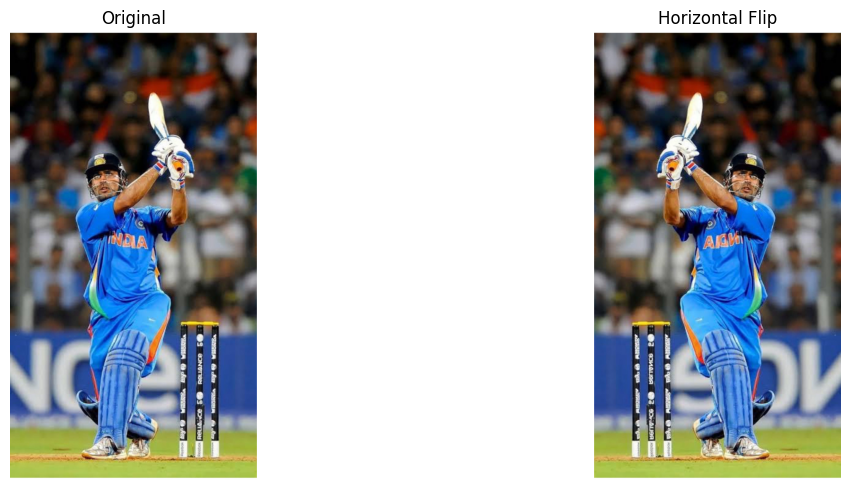

In [3]:
# horizontal flip

horizontal_flip = transforms.RandomHorizontalFlip(p=1.0)

flipped = horizontal_flip(image)

show_images(
    [image, flipped],
    ["Original", "Horizontal Flip"]
)

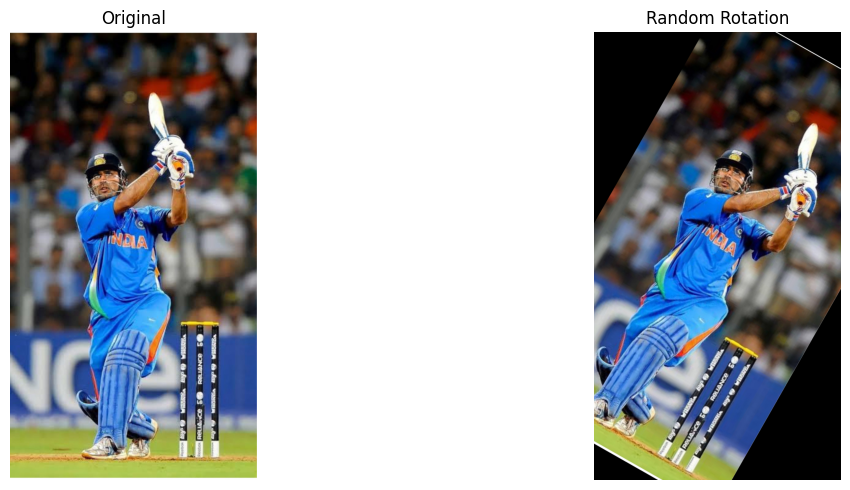

In [4]:
# rotation 

rotate = transforms.RandomRotation(degrees=30)

rotated = rotate(image)

show_images(
    [image, rotated],
    ["Original", "Random Rotation"]
)

Width: 1320
Height: 2400


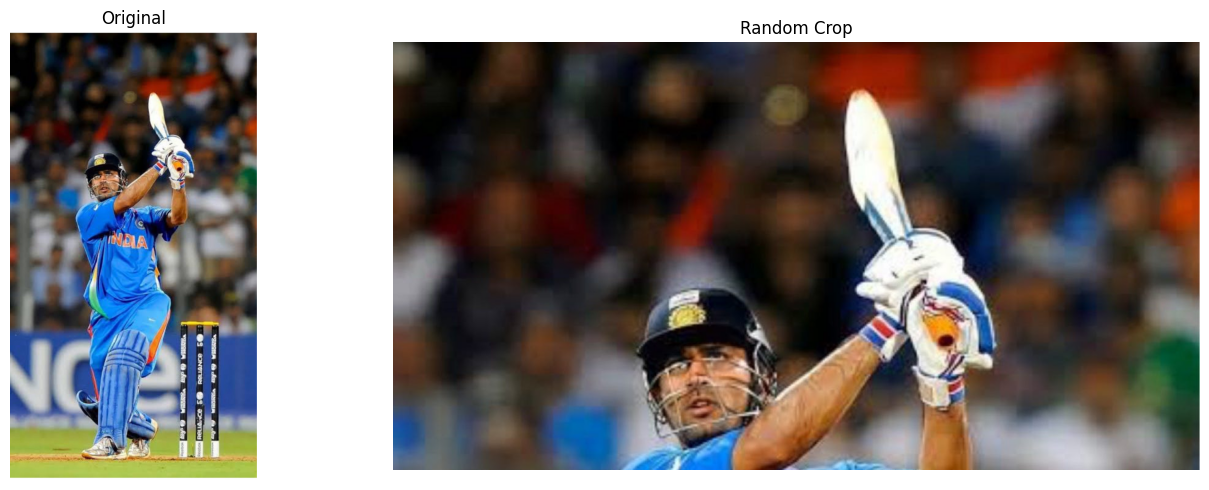

In [9]:
# Random Crop 

width, height = image.size

print("Width:", width)
print("Height:", height)

crop_size = (min(700, height), min(1500, width))

random_crop = transforms.RandomCrop(size=crop_size)

cropped = random_crop(image)

show_images(
    [image, cropped],
    ["Original", "Random Crop"]
)

Original size: (1320, 2400)
Output size: (224, 224)


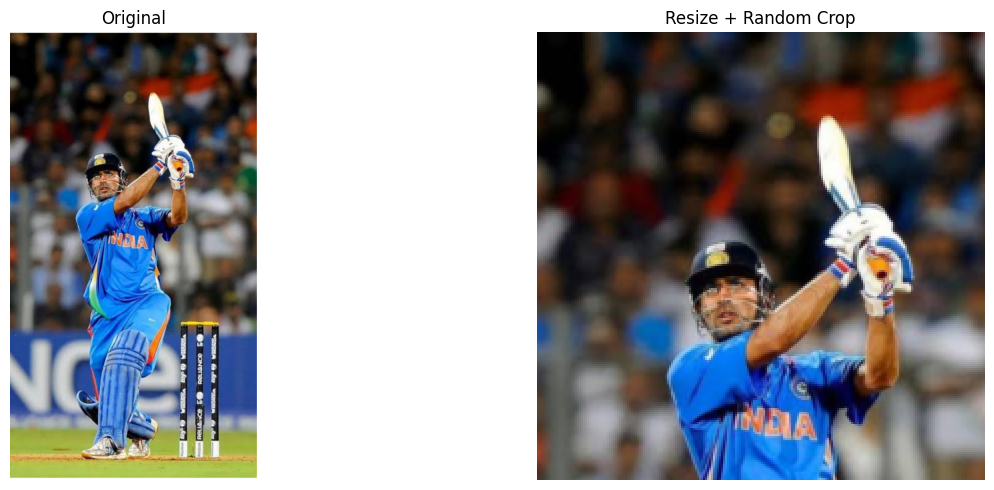

In [10]:
# Resize + crop

resize_crop = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224)
])

resized_cropped = resize_crop(image)

print("Original size:", image.size)
print("Output size:", resized_cropped.size)

show_images(
    [image, resized_cropped],
    ["Original", "Resize + Random Crop"]
)

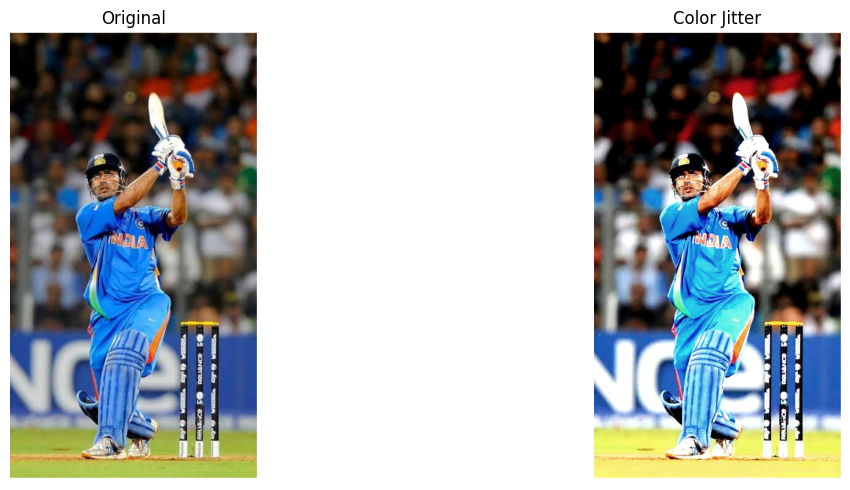

In [14]:
# Color transformations

color_transform = transforms.ColorJitter(
    brightness=0.4,
    contrast=0.4,
    saturation=0.4,
    hue=0.05
)

color_changed = color_transform(image)

show_images(
    [image, color_changed],
    ["Original", "Color Jitter"]
)

In [15]:
train_augmentation = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.03
    ),
    transforms.ToTensor()
])

augmented_tensor = train_augmentation(image)

print("Shape:", augmented_tensor.shape)
print("Dtype:", augmented_tensor.dtype)
print("Min:", augmented_tensor.min().item())
print("Max:", augmented_tensor.max().item())

Shape: torch.Size([3, 224, 224])
Dtype: torch.float32
Min: 0.0
Max: 1.0


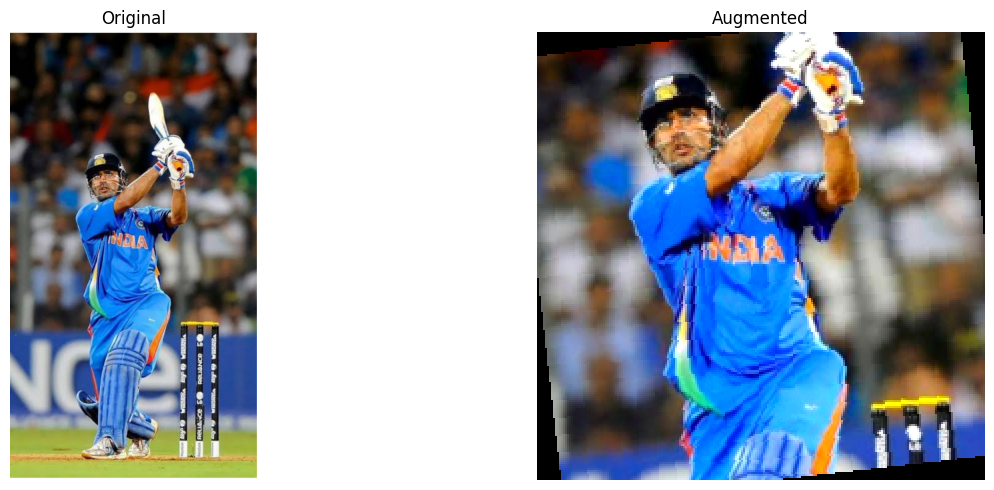

In [16]:
augmented_image = augmented_tensor.permute(1, 2, 0).numpy()

show_images(
    [image, augmented_image],
    ["Original", "Augmented"]
)

In [17]:
output_path = "images/augmented_sample.jpg"

augmented_pil = transforms.ToPILImage()(augmented_tensor)
augmented_pil.save(output_path)

print("Saved:", output_path)

Saved: images/augmented_sample.jpg
